# Exercise 3

## 3.1

In [17]:
import pandas as pd
import numpy as np
# import the dataset
csvname = "student_debt_data.csv"
data = np.asarray(pd.read_csv(csvname,header = None))

In [18]:
# extract input
x = data[:,0]
x.shape = (len(x),1)
# pad input with ones
o = np.ones((len(x),1))
x_new = np.concatenate((o,x),axis = 1)

# extract output
y = data[:,1]

In [19]:
# Solving the least squares problem
# definition of the error function
def MSE(w, x, y):
	return np.sum((y - x.dot(w))**2) / len(y)

# computing the gradient and the hessien functions
def gradient(w, x, y):
	return 2 * np.dot(x.T, (x.dot(w) - y)) / len(y)

def hessian(w, x, y):
	return 2 * np.dot(x.T, x) / len(y)

# Newton's method
def newton_method(x, y, w):
    w_new = w - np.linalg.inv(hessian(w, x, y)).dot(gradient(w, x, y))
    return w_new

# parameters
w = np.array([0,0])
w_hat = newton_method(x_new, y, w)

# output results
print("The optimal weights are: ", w_hat)
print("The mean squared error is: ", MSE(w_hat, x_new, y))

The optimal weights are:  [-1.60729045e+02  8.03244175e-02]
The mean squared error is:  0.00018305954521613313


## 3.2

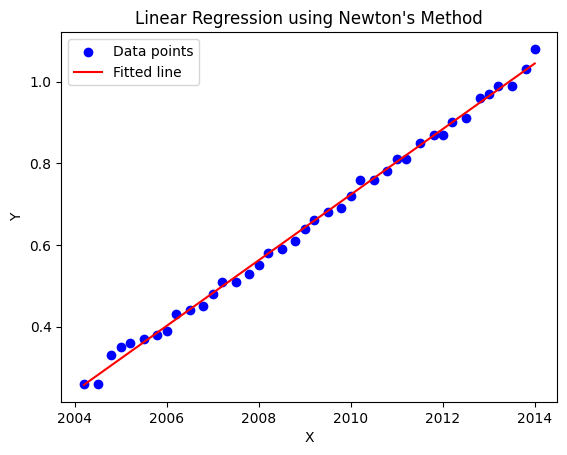

In [20]:
# predicted output
y_hat = x_new.dot(w_hat)

# plots
import matplotlib.pyplot as plt
plt.scatter(x, y, color='blue', label='Data points')
plt.plot(x, y_hat, color='red', label='Fitted line')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Linear Regression using Newton\'s Method')
plt.legend()
plt.show()

## 3.3

In [21]:
# prediction of the student debt at 2050
x_pred = np.array([1, 2050])
y_pred = x_pred.dot(w_hat)
print("The predicted student debt at 2050 is: ", y_pred)

The predicted student debt at 2050 is:  3.936010564159642
